In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

In [2]:
emotion_data = load_dataset("dair-ai/emotion")

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [3]:
emotion_data

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [4]:
train_text = emotion_data['train']['text']
train_label = emotion_data['train']['label']

test_text = emotion_data['test']['text']
test_label = emotion_data['test']['label']

In [5]:
label_names = emotion_data['train'].features['label'].names
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [6]:
df_train = pd.DataFrame({
    'text' : train_text,
    'label' : [label_names[i] for i in train_label]
})

df_test = pd.DataFrame({
    'text' : test_text,
    'label' : [label_names[i] for i in test_label]
})

In [7]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


<Axes: xlabel='label', ylabel='count'>

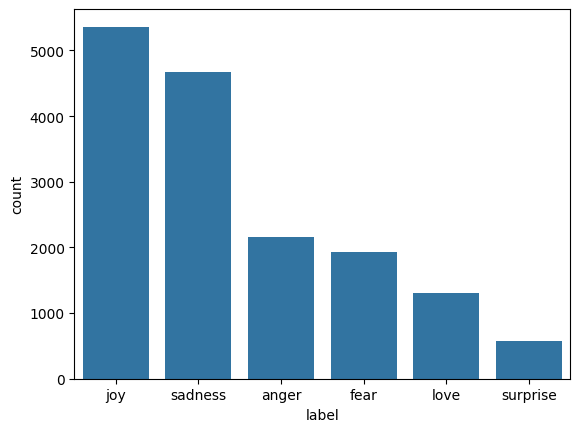

In [8]:
sns.countplot(x='label',data = df_train,order=df_train['label'].value_counts().index)

In [9]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000

tokenizer = Tokenizer(num_words = max_words,oov_token = '')
tokenizer.fit_on_texts(df_train['text'])

train_sequences = tokenizer.texts_to_sequences(df_train['text'])
test_sequences = tokenizer.texts_to_sequences(df_test['text'])

train_padd = pad_sequences(train_sequences,maxlen = 50,padding = 'post' , truncating = 'post')
test_padd = pad_sequences(test_sequences,maxlen = 50,padding = 'post' , truncating = 'post')

train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_class = len(np.unique(train_labels))
num_class


6

In [10]:
print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {max(len(seq) for seq in train_sequences)}")

Vocabulary Size: 15213
Max Sentence Length: 66


In [11]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

class_weight_dict = dict(enumerate(class_weights))
class_weight_dict

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [12]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 3,
    restore_best_weights = True
)

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,Dense,Dropout,LSTM,GRU,Embedding

In [14]:
rnn_model = Sequential([
    Embedding(input_dim = max_words,output_dim = 128,input_length = 50),
    SimpleRNN(units = 128,return_sequences = True),
    Dropout(0.5),
    SimpleRNN(units = 64),
    Dropout(0.5),
    Dense(units = num_class,activation = 'softmax')
])
rnn_model.compile(optimizer='adam',loss = 'sparse_categorical_crossentropy',metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [15]:
rnn_model.fit(
    train_padd, train_labels,
    validation_data=(test_padd, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(test_padd, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 50ms/step - accuracy: 0.1573 - loss: 2.0673 - val_accuracy: 0.2535 - val_loss: 1.7755
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 51ms/step - accuracy: 0.1414 - loss: 1.8942 - val_accuracy: 0.0330 - val_loss: 1.8357
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 26s 53ms/step - accuracy: 0.1274 - loss: 1.8276 - val_accuracy: 0.2735 - val_loss: 1.7890
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 51ms/step - accuracy: 0.1354 - loss: 1.8088 - val_accuracy: 0.1110 - val_loss: 1.7716
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 43s 55ms/step - accuracy: 0.1427 - loss: 1.8065 - val_accuracy: 0.3525 - val_loss: 1.7464
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 33s 66ms/step - accuracy: 0.1490 - loss: 1.8022 - val_accuracy: 0.1380 - val_loss: 1.8634
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 53ms/step - accuracy: 0.1533 - loss: 1.8007 - val_accuracy: 0.1120 - val_loss: 1.7839
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 26s 52ms/step - accuracy: 0.1452 - loss: 1.8035 - 

In [16]:
lstm_model = Sequential([
    Embedding(input_dim = max_words,output_dim = 128,input_length = 50),
    LSTM(units= 128,return_sequences = True),
    Dropout(0.5),
    LSTM(units = 64),
    Dropout(0.5),
    Dense(units = num_class,activation = 'softmax')
])

lstm_model.compile(optimizer='adam',loss = 'sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    train_padd,train_labels,
    validation_data = (test_padd,test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

lstm_loss,lstm_acc = lstm_model.evaluate(test_padd,test_labels)
print(f"LSTM Loss:{lstm_loss}")
print(f"LSTM Accuracy:{lstm_acc}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 72s 136ms/step - accuracy: 0.1609 - loss: 1.7949 - val_accuracy: 0.1385 - val_loss: 1.8009
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 134ms/step - accuracy: 0.1556 - loss: 1.7944 - val_accuracy: 0.1180 - val_loss: 1.7937
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 134ms/step - accuracy: 0.1657 - loss: 1.7927 - val_accuracy: 0.0470 - val_loss: 1.7946
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.1385 - loss: 1.8009
LSTM Loss:1.8008664846420288
LSTM Accuracy:0.13850000500679016


In [17]:
gru_model = Sequential([
    Embedding(input_dim = max_words,output_dim = 128,input_length = 50),
    GRU(units = 128,return_sequences = True),
    Dropout(0.5),
    GRU(units = 64),
    Dropout(0.5),
    Dense(units = num_class,activation = 'softmax')
])

gru_model.compile(optimizer = 'adam' , loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

gru_model.fit(
    train_padd,train_labels,
    validation_data = (test_padd,test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

gru_loss,gru_acc = gru_model.evaluate(test_padd,test_labels)
print(f"GRU Loss:{gru_loss}")
print(f"GRU Accuracy:{gru_acc}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 61s 116ms/step - accuracy: 0.1524 - loss: 1.7968 - val_accuracy: 0.0345 - val_loss: 1.7862
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 58s 116ms/step - accuracy: 0.1536 - loss: 1.7953 - val_accuracy: 0.1395 - val_loss: 1.7761
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 58s 116ms/step - accuracy: 0.1386 - loss: 1.7948 - val_accuracy: 0.1380 - val_loss: 1.7947
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.0345 - loss: 1.7862
GRU Loss:1.7861908674240112
GRU Accuracy:0.03449999913573265


In [18]:
results_df = pd.DataFrame({
    'Models' : ['RNN','LSTM','GRU'],
    'Loss' : [rnn_loss,lstm_loss,gru_loss],
    'Accuracy' : [rnn_accuracy,lstm_acc,gru_acc]
}).sort_values(by='Accuracy',ascending=False)
results_df

,Models,Loss,Accuracy
0,RNN,1.746373,0.3525
1,LSTM,1.800866,0.1385
2,GRU,1.786191,0.0345


In [20]:
!wget http://nlp.stanford.edu/data/glove.6B.zip

# Unzip
!unzip glove.6B.zip

--2026-10-13 12:44:33--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2026-10-13 12:44:33--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2026-10-13 12:44:34--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

In [21]:
glove_dict = {}

with open("glove.6B.300d.txt", encoding="utf8") as f:
    for line in f:
        values = line.split()
        word = values[0]
        vector = np.asarray(values[1:], dtype="float32")
        glove_dict[word] = vector

print(f"Loaded {len(glove_dict)} words from GloVe!")

Loaded 400000 words from GloVe!


In [22]:
embedding_dim = 300

# Create a matrix of zeros (Shape: 10000 rows, 300 columns)
embedding_matrix = np.zeros((max_words, embedding_dim))

# Loop through your tokenizer's vocabulary
for word, i in tokenizer.word_index.items():
    if i < max_words:
        # Look up the word in GloVe's dictionary
        embedding_vector = glove_dict.get(word)
        if embedding_vector is not None:
            # If GloVe knows this word, put its vector into our matrix!
            embedding_matrix[i] = embedding_vector

In [27]:
from tensorflow.keras.layers import Bidirectional

br_model = Sequential([
    Embedding(input_dim=max_words,
              output_dim=embedding_dim,
              input_length=50,
              weights=[embedding_matrix],
              trainable=True),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(units=num_class, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [28]:
br_model.compile(optimizer = 'adam' , loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

br_model.fit(
    train_padd,train_labels,
    validation_data = (test_padd,test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

br_loss,br_acc = br_model.evaluate(test_padd,test_labels)
print(f"Bidirectional RNN Loss:{br_loss}")
print(f"Bidirectional RNN Accuracy:{br_acc}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 189s 363ms/step - accuracy: 0.6191 - loss: 0.9306 - val_accuracy: 0.8940 - val_loss: 0.3419
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 196s 350ms/step - accuracy: 0.9173 - loss: 0.2265 - val_accuracy: 0.9245 - val_loss: 0.1839
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 174s 347ms/step - accuracy: 0.9393 - loss: 0.1568 - val_accuracy: 0.9280 - val_loss: 0.1893
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 173s 346ms/step - accuracy: 0.9574 - loss: 0.1127 - val_accuracy: 0.9260 - val_loss: 0.2122
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 176s 353ms/step - accuracy: 0.9662 - loss: 0.0921 - val_accuracy: 0.9230 - val_loss: 0.2227
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - accuracy: 0.9245 - loss: 0.1839
Bidirectional RNN Loss:0.18387199938297272
Bidirectional RNN Accuracy:0.9244999885559082


63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step


<Axes: >

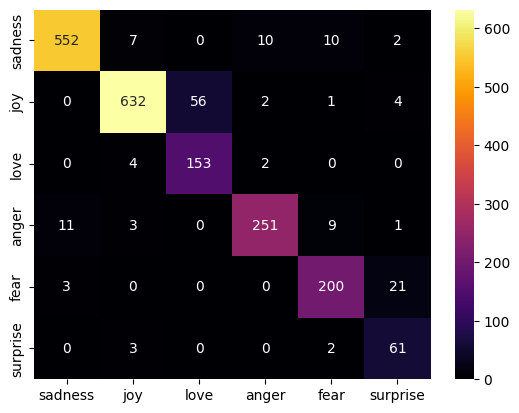

In [29]:
from sklearn.metrics import confusion_matrix

br_prediction = np.argmax(br_model.predict(test_padd),axis=1)

sns.heatmap(confusion_matrix(test_labels, br_prediction),annot=True, fmt='d', cmap='inferno', xticklabels=label_names, yticklabels=label_names)

In [31]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel deep love and romantic affection for my partner",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!",
    "I love her so much man,but i lost her"
]

sample_seq = tokenizer.texts_to_sequences(sample_texts)
sample_seq_padd = pad_sequences(sample_seq,maxlen = 50,padding = 'post' , truncating = 'post')

br_predictions = np.argmax(br_model.predict(sample_seq_padd),axis=1)
for i in range(len(sample_texts)):
    print(f"Text: {sample_texts[i]}")
    print(f"Predicted Label: {label_names[br_predictions[i]]}")
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Label: joy

Text: I feel deep love and romantic affection for my partner
Predicted Label: love

Text: I feel so alone and hopeless today.
Predicted Label: sadness

Text: I am furious that they cancelled the trip at the last minute.
Predicted Label: anger

Text: I feel terrified when walking down dark alleyways alone.
Predicted Label: fear

Text: I was shocked and completely surprised by the unexpected gift!
Predicted Label: surprise

Text: I love her so much man,but i lost her
Predicted Label: sadness



In [32]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir,exist_ok = True)
br_model.save(os.path.join(model_dir,'BiGRU_model.keras'))

with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
  pickle.dump(tokenizer,file)